In [4]:
#increase the display size to 95% of window width
from IPython.display import display, HTML
display(HTML("<style>.container { width:95% !important; }</style>"))
display(HTML("<style>.output_result { max-width:95% !important; }</style>"))


import os
import sys
import string
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

path = os.getcwd().split('/')
machine_path = '/'+path[1]+'/'+path[2] #cat the /home/user/ or /Users/user from system using path

sys.path.append(f"{machine_path}/opt/post_processing") #functions/mandyocIO.py, if the notebook is not run from post_processing
from functions.mandyocIO import (read_tapioca_datasets, read_params, read_times_steps, find_nearest, trim_axs,
                                 measure_crustal_thickness, measure_margins_width, plot_property)

##File of fancy plot style. To use des.mplstyle file you must have an LaTeX distribution in your system
#plt.style.use(machine_path+'/Mestrado/cenarios/mandyoc/scripts_gera_inputs_imgs/new_outputs/des.mplstyle')

In [16]:
# model_path = '/Volumes/Joao_Macedo/tests_rft/Ho35S1_dz05_Clc10_Cmlit025_Ts0_1080'
# model_path = '/Volumes/Joao_Macedo/tests_rft/Ho35S1_Clc10_Cmlit025_Ts0_1080'

# model_path = '/Volumes/Joao_Macedo/tests_rft/Ho35S1_Clc40_Cmlit025_Ts0_1080'
model_path = '/Volumes/Joao_Macedo/tests_rft/Ho35S1_Clc40_Cmlit025_Ts0_1090'
# model_path = '/Volumes/Joao_Macedo/tests_rft/Ho35S1_Clc40_Cmlit025_Ts0_1100'

density_data = xr.open_dataset(f"{model_path}/density.nc", cache=False, engine="h5netcdf")["density"]
# Nx = len(density_data.x)
# Nz = len(density_data.z)
# Lx = density_data.x.values[-1]/1000
# Lz = density_data.z.values[-1]/1000
time = xr.open_dataset(f"{model_path}/density.nc", cache=False, engine="h5netcdf")["time"]
t = 40 #Myr
idx = find_nearest(time.values, t)

litho_data = xr.open_dataset(f"{model_path}/lithology.nc", cache=False, engine="h5netcdf")["lithology"]
x = litho_data.x.values / 1000
z = litho_data.z.values / 1000
dz = (z[-1] - z[0]) / (len(z) - 1)  # 0.1 km

litho_i = litho_data.sel(time=t, method="nearest").values
cond = (litho_i == 1) | (litho_i == 3)

# thickness_lithospheric_mantle = np.sum(cond, axis=0)/(5/dz)
thickness_lithospheric_mantle = np.sum(cond, axis=0)*dz

(800.0, 1200.0)

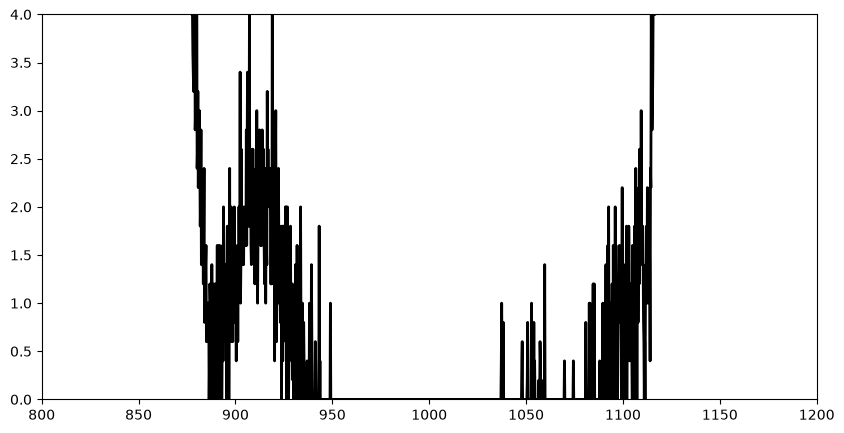

In [17]:
plt.close()
fig, axs = plt.subplots(1, 1, figsize=(10, 5))
axs.plot(x[:-1], thickness_lithospheric_mantle[:-1], color='k', lw=2)
axs.set_ylim(0, 4)
axs.set_xlim(800, 1200)